# Verification of `model/solver.py`

Every test here imports and runs the one solver in `model/solver.py`.

## Test 3: Energy budget

The solver is a finite-volume scheme, so energy should be conserved exactly
(to rounding error). Over any run, the change in stored enthalpy must equal
the heat in through the bed minus the heat out through the surface:

$$\Delta \int_0^H E\,dz = \int_0^t (q_\text{bed} - q_\text{surface})\,dt' \qquad [\mathrm{J\,m^{-2}}]$$

We check this for both basal boundary conditions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from model.solver import Params, run, SECONDS_PER_YEAR

In [2]:
def energy_residual(res):
    """Stored-energy change minus net boundary input [J m^-2], at each snapshot."""
    stored_change = res.energy_stored - res.energy_stored[0]
    net_input = res.energy_in_base - res.energy_out_top
    return stored_change - net_input

cases = {
    "fixed basal flux (q_b = 5 W m$^{-2}$)": Params(basal_bc="flux"),
    "fixed basal temperature (T_b = 278.15 K)": Params(basal_bc="temperature"),
}
results = {name: run(p) for name, p in cases.items()}

for name, res in results.items():
    resid = energy_residual(res)
    # Compare against the total heat that crossed the boundaries.
    scale = np.abs(res.energy_in_base).max() + np.abs(res.energy_out_top).max()
    rel = np.abs(resid).max() / scale
    print(f"{name}: max |residual| = {np.abs(resid).max():.3e} J m^-2, relative = {rel:.3e}")
    assert rel < 1e-10, "energy is not conserved"
print("PASS: energy is conserved to rounding error for both boundary conditions")

fixed basal flux (q_b = 5 W m$^{-2}$): max |residual| = 1.923e-03 J m^-2, relative = 1.193e-13
fixed basal temperature (T_b = 278.15 K): max |residual| = 1.335e-05 J m^-2, relative = 4.583e-15
PASS: energy is conserved to rounding error for both boundary conditions


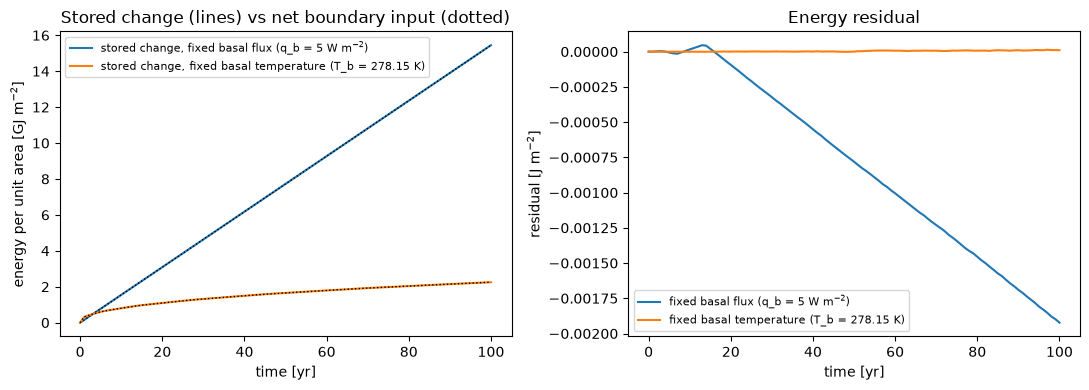

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, res in results.items():
    t_yr = res.t / SECONDS_PER_YEAR
    axes[0].plot(t_yr, (res.energy_stored - res.energy_stored[0]) / 1e9, label=f"stored change, {name}")
    axes[0].plot(t_yr, (res.energy_in_base - res.energy_out_top) / 1e9, "k:", lw=1)
    axes[1].plot(t_yr, energy_residual(res), label=name)
axes[0].set_xlabel("time [yr]")
axes[0].set_ylabel("energy per unit area [GJ m$^{-2}$]")
axes[0].set_title("Stored change (lines) vs net boundary input (dotted)")
axes[0].legend(fontsize=8)
axes[1].set_xlabel("time [yr]")
axes[1].set_ylabel("residual [J m$^{-2}$]")
axes[1].set_title("Energy residual")
axes[1].legend(fontsize=8)
fig.tight_layout()